# Lapis 3 — kalibrasi, conformal, selective prediction
CV (`scripts/l3_eval.py --tag final_cv`), parameter produksi (`scripts/l3_production.py`, D-20/D-21), dan test (`scripts/final_eval.py`).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from remediaide_ml.paths import TABLES, FIGURES, PROCESSED
pd.set_option("display.precision", 4)
def js(name): return json.loads((TABLES / name).read_text())

## CV

In [2]:
cv = js('E5_l3_final_cv.json'); pd.DataFrame({k: {kk: vv for kk, vv in v.items() if not isinstance(vv, dict)} for k, v in cv.items() if isinstance(v, dict)})

,L1,L2
calibrator,temperature,NaN
temperature,0.9724,1.2019
n_cal,45645,NaN
n_eval,171835,NaN
ece_before,0.005,0.0254
ece_after,0.0037,0.0096
macro_f1_after,0.4816,NaN
misgroup_after,0.3515,NaN
lac_qhat,0.8294,NaN
coverage,0.8903,0.9504


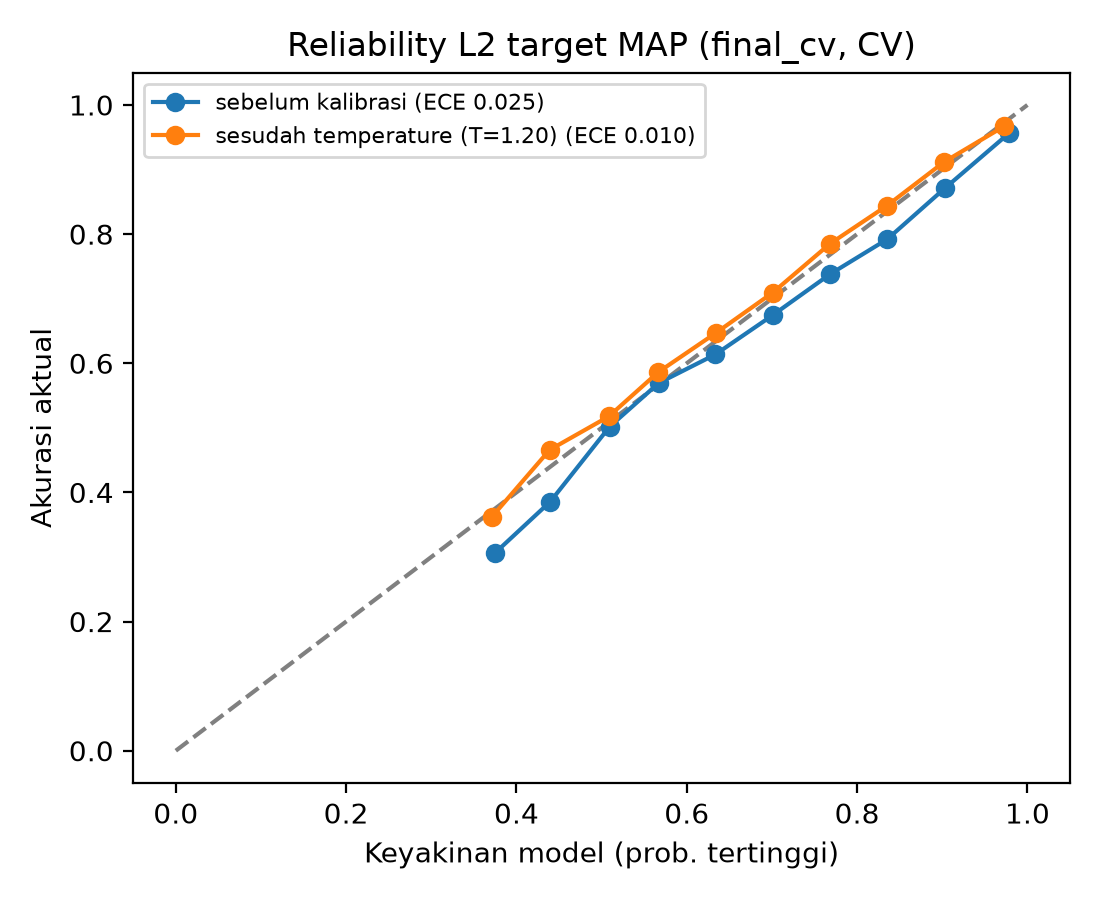

In [3]:
display(Image(FIGURES / 'E5_reliability_L2_final_cv.png', width=480))

## Parameter produksi (siswa kalibrasi model CO-KT final)

In [4]:
json.loads((TABLES.parent.parent / 'models' / 'l3_conformal_v1.json').read_text())

{'alpha': 0.1,
 'l1_temperature': 1.0125947523113925,
 'l1_lac_qhat': 0.8371441506753501,
 'l1_doubt_threshold': 0.525368172682699,
 'l1_operating_point': {'defer_rate': 0.2,
  'rule': 'no grid point met 25% reduction within 30% -> fallback 20% (D-09)'},
 'l1_bin_temperature': 0.9751038310692324,
 'mastery_prior': 0.4952155850105684,
 'source': 'scripts/l3_production.py (calibration users of the production CO-KT; CV OOF calibration rows for L2)',
 'l2_tfidf': {'temperature': 1.2019477581500233,
  'aps_qhat': 0.9942362310145121,
  'hidden_threshold': 0.2},
 'l2_mdeberta': {'temperature': 1.4124958591718477,
  'aps_qhat': 0.9842566907917449,
  'hidden_threshold': 0.25},
 'l2_by_lang': {'en': 'tfidf', 'id': 'mdeberta'},
 'hidden_threshold': 0.25}

## Test (dibuka sekali, T46)

In [5]:
pd.Series(js('E5_test.json'))

ece_before                                                                       0.0063
ece_after                                                                        0.0068
lac_coverage                                                                     0.9003
lac_avg_set_size                                                                 1.8976
lac_singleton_share                                                              0.2956
defer_rate_at_production_threshold                                               0.2056
production_defer_target               {'defer_rate': 0.2, 'rule': 'no grid point met...
misgroup_no_defer                                                                0.3474
misgroup_kept                                                                    0.2831
ece_bin_needs_remediation                                                        0.0156
n_rows                                                                            58963
dtype: object

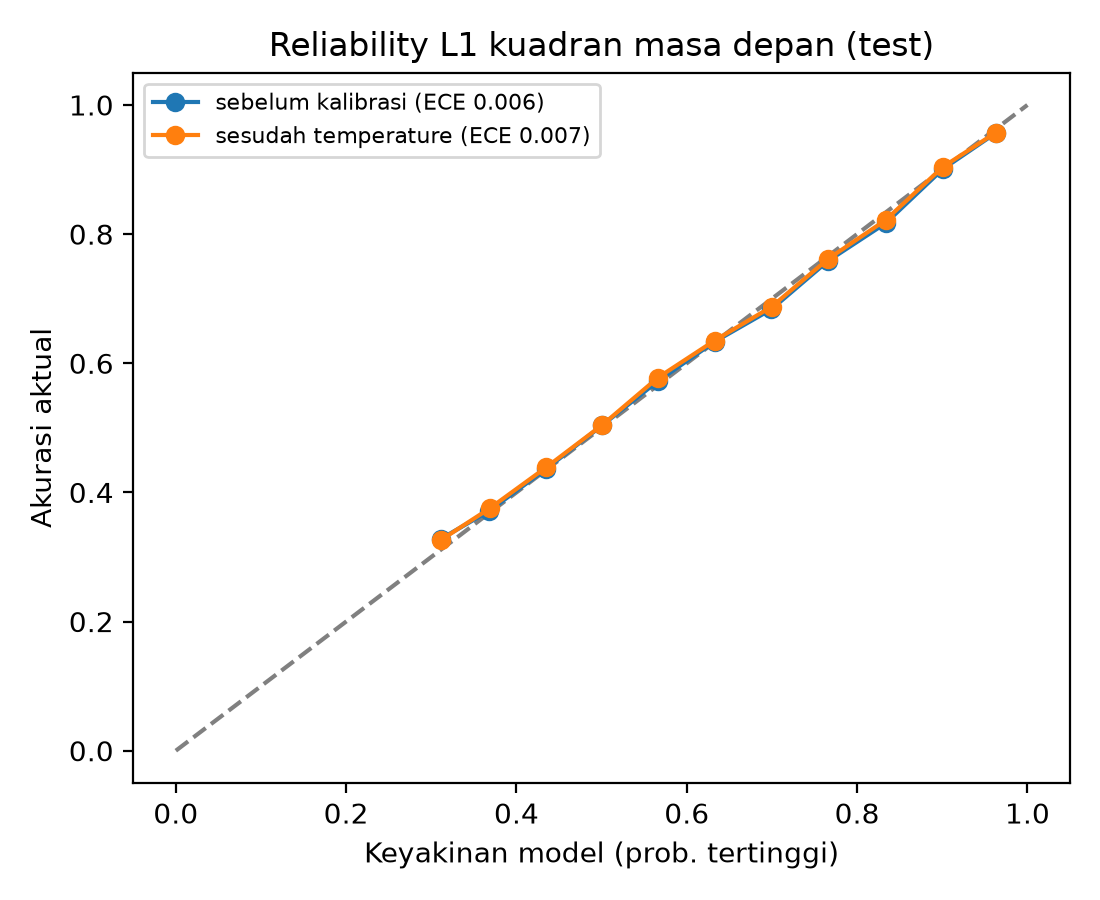

In [6]:
display(Image(FIGURES / 'E5_reliability_L1.png', width=480))

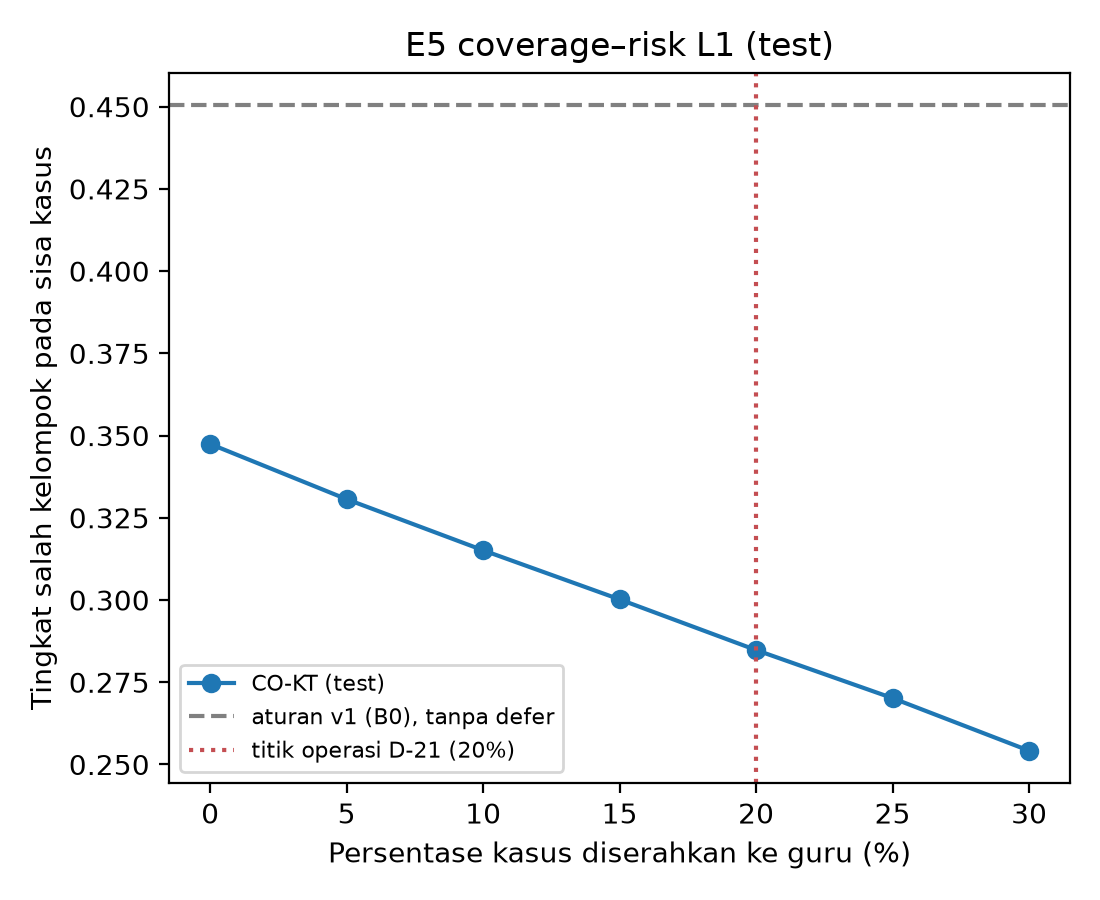

In [7]:
display(Image(FIGURES / 'E5_coverage_risk.png', width=480))

In [8]:
pd.read_csv(TABLES / 'E5_coverage_risk_L1_test.csv')

,defer_rate,coverage,risk,relative_reduction,errors_caught_share
0,0.00,1.00,0.3474,0.0000,0.0000
1,0.05,0.95,0.3306,0.0483,0.0959
2,0.10,0.90,0.3151,0.0930,0.1837
3,0.15,0.85,0.3002,0.1360,0.2656
4,0.20,0.80,0.2848,0.1803,0.3443
5,0.25,0.75,0.2702,0.2224,0.4168
6,0.30,0.70,0.2542,0.2684,0.4879
